In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

import seaborn as sns
from pathlib import Path
import pickle
import glob
import re
import anndata as ad
import scanpy as sc
from adjustText import adjust_text

from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

import scipy.sparse as sp
from scipy import stats
from statsmodels.stats.multitest import multipletests
import os

In [2]:
#### Set plotting parameters
mpl.rcParams.update({
    "font.family":        "Liberation Sans",
    "pdf.fonttype":       42,   # TrueType → keeps glyphs grouped in Illustrator
    "ps.fonttype":        42,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.25,
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.minor.width":  0.5,
    "ytick.minor.width":  0.5,
    "xtick.major.size":   3.5,
    "ytick.major.size":   3.5,
    "axes.labelsize":     6,
    "xtick.labelsize":    6,
    "ytick.labelsize":    6,
    "legend.fontsize":    5,
    "axes.titlesize":     7,
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.transparent": False,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.05,
})

### inches to points conversion
MM = 1 / 25.4

In [3]:
## Helpers

# KM plot
NATURE_15COL_MM = 120               # Nature 1.5-column width
 
KM_COL = {'high': '#B4436C', 'low': '#4C78A8'}
  
def _sig(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
 
 
def km_cox_two_endpoints(
    d,
    score='box_frac',
    title='fraction ENPP2\u2013LPAR1 pairs',
    endpoints=None,
    use_histology=True,     # add histology_Astro covariate (Astro = reference)
    use_sex=False,          # add sex_male covariate (Female = reference)
    check_assumptions=True,
    out_path=None,
):
    if endpoints is None:
        endpoints = [
            dict(name='Recurrence', status_col='recurrance_status', pos='rec',
                 dur_col='surgical_interval_sample_to_next_rec',
                 xlabel='time to recurrence', ylabel='recurrence-free probability'),
            dict(name='Transformation', status_col='progression_status', pos='transformed',
                 dur_col='MT_interval_yr',
                 xlabel='years to transformation', ylabel='transformation-free probability'),
        ]
 
    # Nature 1.5-column: endpoints side by side, each ~half the width
    n_ep = len(endpoints)
    fig, axes = plt.subplots(1, n_ep,
                             figsize=(NATURE_15COL_MM * MM, 60 * MM),
                             squeeze=False)
    axes = axes[0]
    results = {}
 
    for ax, ep in zip(axes, endpoints):
        dd = d.copy()
        dd['event'] = (dd[ep['status_col']].astype(str).str.lower() == ep['pos']).astype(int)
        dd['duration'] = pd.to_numeric(dd[ep['dur_col']], errors='coerce')
        dd = dd.dropna(subset=['duration', score])
 
        # ── median split + KM ──────────────────────────────────────────────
        cut = float(np.median(dd[score]))
        hi = dd[dd[score] > cut]
        lo = dd[dd[score] <= cut]
        for arm, ls, name in [(hi, '-', 'high'), (lo, '--', 'low')]:
            KaplanMeierFitter().fit(arm['duration'], arm['event'], label=f"{name} (n={len(arm)})") \
                .plot_survival_function(ax=ax, ci_show=False, linestyle=ls,
                                        color=KM_COL[name], linewidth=1.0,
                                        show_censors=True,
                                        censor_styles={'marker': '|', 'ms': 6, 'mew': 1.0})
    
        lr = logrank_test(hi['duration'], lo['duration'],
                          event_observed_A=hi['event'], event_observed_B=lo['event'])
 
        # ── Cox PH: hazard ratio for the score (per SD), adjusted ───────────
        dd['score_z'] = (dd[score] - dd[score].mean()) / dd[score].std()
        cov = ['score_z']
        if use_histology and 'histology' in dd:
            dd['histology_Astro'] = (dd['histology'] == 'Astro').astype(int)   # Astro = ref
            cov.append('histology_Astro')
        if use_sex and 'patient_sex' in dd:
            dd['sex_male'] = (dd['patient_sex'] == 'M').astype(int)             # Female = ref
            cov.append('sex_male')
 
        HR = lo95 = hi95 = cox_p = np.nan
        cph = CoxPHFitter()
        try:
            model_df = dd[['duration', 'event'] + cov]
            cph.fit(model_df, duration_col='duration', event_col='event', strata='histology_Astro')
            print(f"\n===== Cox PH — {ep['name']} (n={len(model_df)}, "
                  f"events={int(dd['event'].sum())}) =====")
            cph.print_summary()
            s = cph.summary.loc['score_z']
            HR, lo95, hi95, cox_p = (s['exp(coef)'], s['exp(coef) lower 95%'],
                                     s['exp(coef) upper 95%'], s['p'])
            if check_assumptions:
                try:
                    cph.check_assumptions(model_df, p_value_threshold=0.05, show_plots=False)
                except Exception as e:
                    print(f"[check_assumptions skipped: {e}]")
        except Exception as e:
            print(f"[Cox failed for {ep['name']}: {e}]")
 
        # ── annotate ────────────────────────────────────────────────────────
        txt = f"log-rank p = {lr.p_value:.3g} ({_sig(lr.p_value)})\nn high = {len(hi)}, n low = {len(lo)}"
        if not np.isnan(HR):
            txt += (f"\nHR (score / SD) = {HR:.2f} [{lo95:.2f}\u2013{hi95:.2f}]"
                    f"\nCox p = {cox_p:.3g} ({_sig(cox_p)})")
        ax.text(0.04, 0.04, txt, transform=ax.transAxes, fontsize=5,
                va='bottom', ha='left',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                          edgecolor='none', alpha=0.8))
        ax.set_title(ep['name'], fontsize=7, fontweight='bold', loc='left')
        ax.set_xlabel(ep['xlabel'])
        ax.set_ylabel(ep['ylabel'])
        ax.set_ylim(0, 1.02)
        ax.legend(loc='upper right', frameon=False, handlelength=1.4)
 
        results[ep['name']] = dict(HR_score_per_SD=HR, HR_lower95=lo95, HR_upper95=hi95,
                                   cox_p=cox_p, logrank_p=lr.p_value,
                                   n_high=len(hi), n_low=len(lo),
                                   n_events=int(dd['event'].sum()))
 
    fig.suptitle(title, fontsize=8, fontweight='bold')
    fig.tight_layout()
    if out_path:
        fig.savefig(out_path, bbox_inches='tight', dpi=200)
        print(f"\nSaved: {out_path}")
 
    res = pd.DataFrame(results).T
    print("\n=== hazard-ratio summary (score effect per SD) ===")
    print(res.to_string())
    return fig, res

In [4]:
# ── File paths — edit these ───────────────────────────────────────────────────
OUT_DIR = 'figures'
os.makedirs(OUT_DIR, exist_ok=True)

___
## KM curve

In [5]:
na_values = ["N/A", "n/a", "NA", "na", "NaN", "nan", "NAN","n/A", "", "None", "none", "NULL", "null", "-", "--",'x']
patient_metadata = pd.read_csv('patient_metadata.csv', dtype={'ID':str}, na_values=na_values, keep_default_na=True)

patient_metadata.head(2)

,Unnamed: 0,patient,ID,tumor_grade,patient_sex,progression_label,histology,preservation_method,IDH_status,MGMT Promoter Methylation,...,initial_diagnosis_yr,surgery_number,recurrance_interval_yr,surgical_interval_sample_to_next_rec,MT_interval_yr,overall_survival_yr,MISC,case_vital_status,recurrance_status,progression_status
0,0,p12,5272,II,M,future stable,Oligo,Fresh Frozen,Mut,positive,...,2023,1,3.0,3.0,3.0,3.0,NaN,alive,no rec,no transformation
1,1,p13,2830,II,M,future MT,Astro,Fresh Frozen,Mut,negative,...,2010,2,4.0,3.0,3.0,10.0,vaccine trial at duke between initial resectio...,deceased,rec,transformed


In [6]:
#get discovery pair - ENPP2:LPAR1
pairs = pd.read_csv('Discovery_Validation_pairs.csv')
disc_pairs = pairs.loc[pairs['cohort'].isin(['discovery'])]
disc_pairs.head(2)

,Unnamed: 0,arm,src_frac,tgt_frac,box_frac,cohort,patient_id,celltype_1,celltype_2,gene_1,gene_2
0,30,MT,0.926952,0.261307,0.278365,discovery,2122,Olig. normal,tumor,ENPP2,LPAR1
1,31,MT,0.961538,0.349073,0.344605,discovery,2411,Olig. normal,tumor,ENPP2,LPAR1


In [7]:
# Plot KM curve
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test

In [8]:
#add metadta
disc_pairs['patient_id'] = disc_pairs['patient_id'].astype(str) 
pairs_mean = disc_pairs.merge(patient_metadata, left_on='patient_id',right_on='ID', how='left')
pairs_mean.head()

/tmp/ipykernel_1851328/1664412730.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disc_pairs['patient_id'] = disc_pairs['patient_id'].astype(str)


,Unnamed: 0_x,arm,src_frac,tgt_frac,box_frac,cohort,patient_id,celltype_1,celltype_2,gene_1,...,initial_diagnosis_yr,surgery_number,recurrance_interval_yr,surgical_interval_sample_to_next_rec,MT_interval_yr,overall_survival_yr,MISC,case_vital_status,recurrance_status,progression_status
0,30,MT,0.926952,0.261307,0.278365,discovery,2122,Olig. normal,tumor,ENPP2,...,2002,3,9.0,9.0,9.0,23.0,patient was diagnosed 2002 then stable recurre...,deceased,rec,transformed
1,31,MT,0.961538,0.349073,0.344605,discovery,2411,Olig. normal,tumor,ENPP2,...,2011,2,4.0,3.0,3.0,10.0,NaN,deceased,rec,transformed
2,32,MT,0.978809,0.226033,0.217971,discovery,2683,Olig. normal,tumor,ENPP2,...,2013,1,2.0,8.0,8.0,10.0,"MRI showed progression in 2 years, not resecta...",deceased,rec,transformed
3,33,MT,0.864592,0.317585,0.296773,discovery,2789,Olig. normal,tumor,ENPP2,...,2014,1,5.0,5.0,5.0,12.0,recurrent tissue was grade III with some diagn...,alive,rec,transformed
4,34,MT,0.896697,0.309478,0.290481,discovery,2830,Olig. normal,tumor,ENPP2,...,2010,2,4.0,3.0,3.0,10.0,vaccine trial at duke between initial resectio...,deceased,rec,transformed



===== Cox PH — Recurrence (n=15, events=9) =====


<lifelines.CoxPHFitter: fitted with 15 total observations, 6 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                   strata = histology_Astro
      baseline estimation = breslow
   number of observations = 15
number of events observed = 9
   partial log-likelihood = -10.21
         time fit was run = 2026-11-09 20:02:37 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
score_z    1.30      3.67      0.70           -0.07            2.67                0.93               14.45

           cmp to    z    p  -log2(p)
covariate                            
score_z      0.00 1.86 0.06      3.99
---
Concordance = 0.71
Partial AIC = 22.42
log-likelihood ratio test = 5.19 on 1 df
-log2(p) of ll-ratio test = 5.46

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'score_z' failed the non-proportional test: p-value is 0.0244.

   Advice 1: the functional form of the variable 'score_z' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'score_z' using pd.cut, and then specify it in
`strata=['score_z', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Intr

<lifelines.CoxPHFitter: fitted with 15 total observations, 7 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                   strata = histology_Astro
      baseline estimation = breslow
   number of observations = 15
number of events observed = 8
   partial log-likelihood = -5.79
         time fit was run = 2026-11-09 20:02:37 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
score_z    2.71     14.98      1.34            0.07            5.34                1.07              209.07

           cmp to    z    p  -log2(p)
covariate                            
score_z      0.00 2.01 0.04      4.50
---
Concordance = 0.89
Partial AIC = 13.58
log-likelihood ratio test = 11.25 on 1 df
-log2(p) of ll-ratio test = 10.29

Proportional hazard assumption looks okay.

Saved: figures/fig5_enpp2_lpar1_KM_curve_init_gradeII.pdf

=== hazard-ratio summary (score effect per SD) ===
                HR_score_per_SD  HR_lower95  HR_upper95     cox_p  logrank_p  n_high  n_low  n_events
Recurrence             3.669436    0.931842   14.449613  0.063024   0.013007     7.0    8.0       9.0
Transformation        14.981006    1.073478  209.068520  0.044148   0.001491     7.0    8.0       8.0


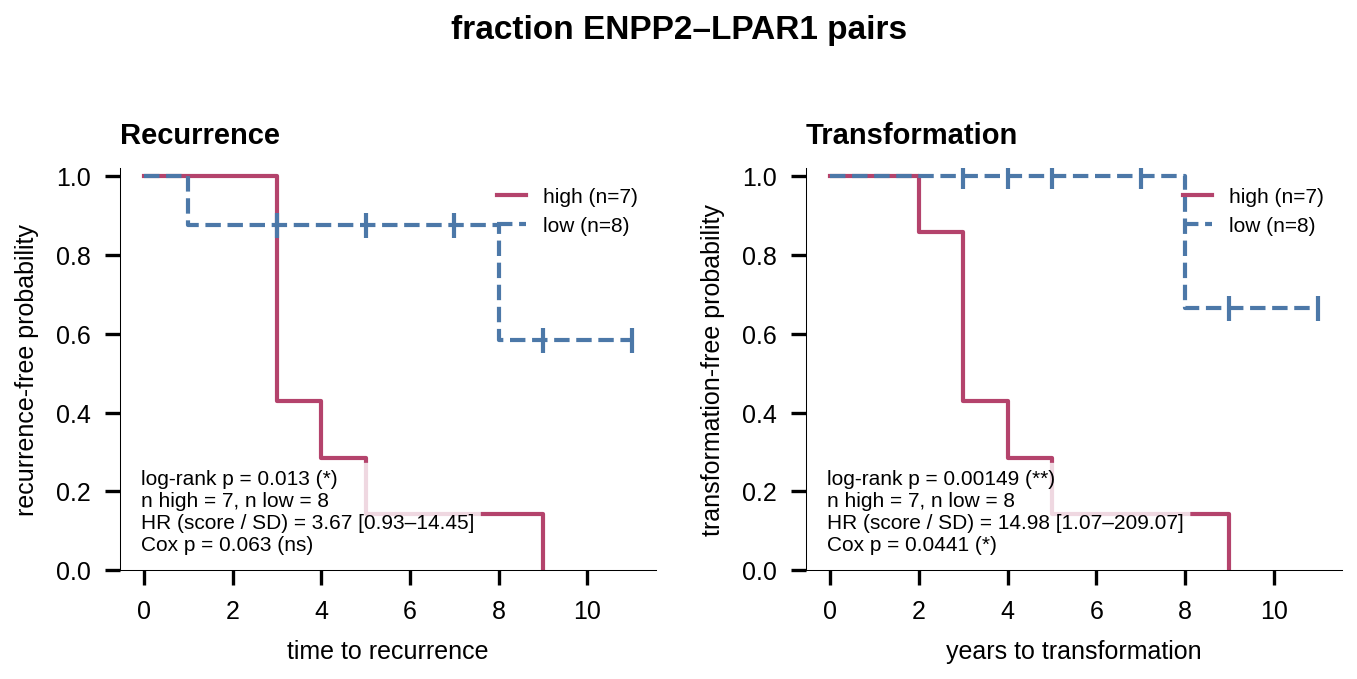

In [11]:
#plot
_, res = km_cox_two_endpoints(pairs_mean, score = 'box_frac', out_path=f'{OUT_DIR}/fig5_enpp2_lpar1_KM_curve_init_gradeII.pdf')